<a href="https://colab.research.google.com/github/myprojectscryoq-lang/Qiskit_Basics/blob/main/qiskit_practise.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install qiskit
!pip install pylatexenc
!pip install qiskit-ibm-runtime
!pip install matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 36.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 88.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 13.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 412.6/412.6 kB 29.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 120.7/120.7 kB 10.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.7/95.7 kB 8.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 113.3/113.3 kB 9.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 234.2/234.2 kB 19.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.8/76.8 kB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 131.0/131.0 kB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 541.5/54

In [ ]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_ibm_runtime import EstimatorV2 as Estimator

In [ ]:
from qiskit.circuit import quantumcircuit
qc= QuantumCircuit(3)
qc.h(0)
qc.p(np.pi/2,0)
qc.cx(0,1)
qc.cx(1,2)

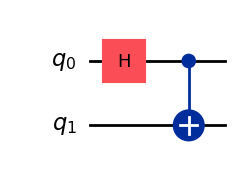

In [ ]:
qc=QuantumCircuit(2)
qc.h(0)
qc.cx(0,1)
qc.draw("mpl")

In [ ]:
observables_labels = ["IZ", "IX", "ZI", "XI", "ZZ", "XX"]
observables = [SparsePauliOp(label) for label in observables_labels]

In [ ]:
from qiskit_ibm_runtime import QiskitRuntimeService

# 1. Initialize the Service using your token
token = "hzs_P3UHjqGQwSIyce0KUehUXVJJ-rmv1zPaagxI674s"
service = QiskitRuntimeService(channel="ibm_quantum_platform", token=token)

# 2. Get the least busy operational backend
backend = service.least_busy(simulator=False, operational=True)
print(f"Using backend: {backend.name}")

# 3. Transpile your circuit (qc) to target the backend (ISA circuit)
pm = generate_preset_pass_manager(backend=backend, optimization_level=1)
isa_circuit = pm.run(qc)

# 4. Construct the Estimator instance with the backend
estimator = Estimator(mode=backend)
estimator.options.resilience_level = 1
estimator.options.default_shots = 5000

# 5. Map the observables to the circuit layout
mapped_observables = [
    observable.apply_layout(isa_circuit.layout) for observable in observables
]

# 6. Run the job
job = estimator.run([(isa_circuit, mapped_observables)])
print(f">>> Job ID: {job.job_id()}")

qiskit_runtime_service._discover_account:WARNING:2026-10-05 09:36:26,448: Loading account with the given token. A saved account will not be used.


InvalidAccountError: 'Unable to retrieve instances. Please check that you are using a valid API token.'

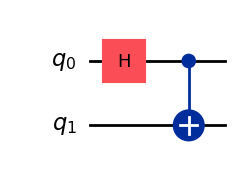

In [ ]:
from qiskit import QuantumCircuit

qc = QuantumCircuit(2)

qc.h(0)
qc.cx(0,1)
qc.draw(output="mpl")

In [ ]:
from qiskit.quantum_info import Pauli
ZZ= Pauli("ZZ")
XX= Pauli("XX")
ZI= Pauli("ZI")
IX= Pauli("IX")
IZ= Pauli("IZ")
XI= Pauli("XI")
observables_labels = [IZ, IX, ZI, XI, ZZ, XX]


In [ ]:
!pip install qiskit_aer

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 37.7 MB/s eta 0:00:00


In [ ]:
from qiskit_aer.primitives import Estimator

estimator = Estimator()
# Create a list of circuits matching the number of observables
job = estimator.run([qc] * len(observables_labels), observables_labels)
result = job.result()
print(result)

EstimatorResult(values=array([ 0.05664062, -0.00976562,  0.05664062, -0.00976562,  1.        ,
        1.        ]), metadata=[{'shots': 1024, 'variance': 0.9967918395996094, 'simulator_metadata': [{'time_taken': 0.005688559, 'num_bind_params': 1, 'parallel_state_update': 2, 'parallel_shots': 1, 'required_memory_mb': 0, 'input_qubit_map': [[1, 1], [0, 0]], 'method': 'stabilizer', 'device': 'CPU', 'num_qubits': 2, 'sample_measure_time': 0.001148495, 'active_input_qubits': [0, 1], 'num_clbits': 2, 'remapped_qubits': False, 'runtime_parameter_bind': False, 'max_memory_mb': 12975, 'noise': 'ideal', 'measure_sampling': True, 'batched_shots_optimization': False, 'fusion': {'enabled': False}}]}, {'shots': 1024, 'variance': 0.9999046325683594, 'simulator_metadata': [{'time_taken': 0.003947843, 'num_bind_params': 1, 'parallel_state_update': 2, 'parallel_shots': 1, 'required_memory_mb': 0, 'input_qubit_map': [[1, 1], [0, 0]], 'method': 'stabilizer', 'device': 'CPU', 'num_qubits': 2, 'sample_meas

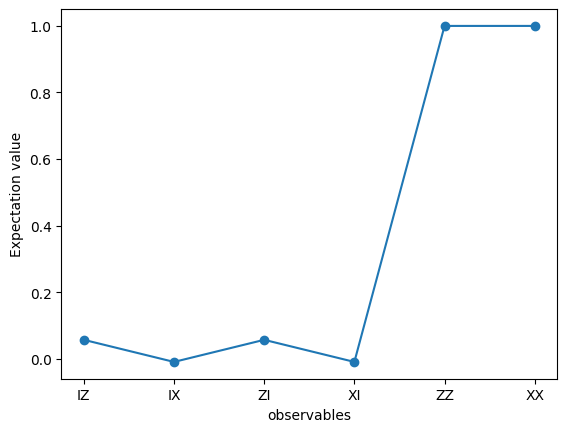

In [ ]:
import matplotlib.pyplot as plt
data=("IZ", "IX", "ZI", "XI", "ZZ", "XX")
values=job.result().values

plt.plot(data, values, "-o")
plt.xlabel("observables")
plt.ylabel("Expectation value")
plt.show()